In [1]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/RNN

/Users/cl1704/PycharmProjects/embedding_dimension/RNN


In [2]:
from Experiment_examples.ParametricWMTask import generate_trials
import pandas as pd
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import gridspec
import seaborn as sns
from Experiment_examples.net import *
import os
import numpy as np
import statsmodels.api as sm
import scipy.optimize as opt
import math
#from psychometrics import *

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import torch
plt.rcParams["axes.grid"] = False
from sklearn.manifold import TSNE
matplotlib.rcParams['axes.linewidth'] = .5

In [14]:
df_list = []
for filename in os.listdir('Experiment_examples/Results'):
    f = os.path.join('Experiment_examples/Results', filename)
    if os.path.isfile(f):
        df_list.append(pd.read_pickle(f))
df = pd.concat(df_list,ignore_index=True)

In [15]:
df

,model_id,w_rec,w_rec_bias,w_in,epochs,sigma_rec,sigma_in,weight_decay,beta,lr,...,gain_target,gain_mean,gain_std,n,dim,pca_error,pca_1,kmeans_error,lambda_gain_mean,lambda_gain_std
0,p0L2fMNv,"[[0.0021005007, 0.023184914, 0.018482028, 0.00...","[0.07684533, 0.051305465, 0.047326904, 0.06082...","[[-0.028203128, -0.012028856], [-0.018693127, ...",500,0,0.0,0.001,20,0.005,...,0.958333,0.967328,0.017641,200,4,0.000971,0.020947,0.101338,1,1
1,srBLJIvB,"[[0.001734118, -0.00779232, -0.00735148, 0.007...","[0.04755227, 0.055841696, 0.052619316, 0.02723...","[[0.006005091, -0.061669882], [0.039659455, 0....",500,0,0.0,0.001,20,0.005,...,0.625000,0.611240,0.048499,200,4,0.000948,0.059361,0.051895,1,1
2,E9Kxyscp,"[[0.0029941618, 0.003874219, -0.0078193545, 0....","[0.0, 0.0, 0.00070471206, 0.0, 0.00061974616, ...","[[0.07049804, -0.006073949], [0.069609605, -0....",500,0,0.0,0.001,20,0.005,...,0.375000,0.374533,0.007557,200,4,0.000022,0.096691,0.004331,1,1
3,NdPqQakh,"[[-0.015406053, -0.013638715, -0.018182382, -0...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[[0.052467287, 0.14693396], [0.05236173, 0.146...",500,0,0.0,0.001,20,0.005,...,0.125000,0.172132,0.002949,200,4,0.000023,0.078208,0.004104,1,1
4,TJImxnGS,"[[0.0012765476, -0.002596617, -0.0026600985, -...","[0.042389523, 0.041755848, 0.04348499, 0.04121...","[[-0.032012425, -0.03999984], [-0.03696059, 0....",500,0,0.0,0.001,20,0.005,...,0.583333,0.582701,0.016789,200,4,0.000131,0.006615,0.014338,1,1
5,crmzcY5D,"[[0.002538939, 0.008956198, 0.0036866178, 0.00...","[0.02909937, 0.040946223, 0.031212388, 0.03344...","[[-0.03511213, 0.08611953], [0.05136512, -0.05...",500,0,0.0,0.001,20,0.005,...,0.583333,0.594937,0.022868,200,4,0.000086,0.098633,0.010351,1,1
6,lxR0bEjn,"[[0.0040486483, 0.0031071142, 0.0008408491, 0....","[0.046708744, 0.057904974, 0.06735443, 0.04158...","[[-0.0024056183, 0.07799747], [0.03560447, -0....",500,0,0.0,0.001,20,0.005,...,0.750000,0.747828,0.034038,200,4,0.003737,0.110172,0.213497,1,1
7,T9ipZsgM,"[[0.0029367341, 0.006064182, 0.009451205, 0.00...","[0.046450768, 0.04481579, 0.05168225, 0.048534...","[[-0.028185913, 0.05571244], [0.051562607, 0.0...",500,0,0.0,0.001,20,0.005,...,0.958333,0.941114,0.028361,200,4,0.001668,0.066624,0.183924,1,1
8,SKT1CKDs,"[[-0.0064059873, -0.008486781, -0.003994113, -...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[[-0.031919207, 0.03290727], [-0.033089627, -0...",500,0,0.0,0.001,20,0.005,...,0.250000,0.256887,0.005620,200,4,0.000034,0.015531,0.006969,1,1
9,IIaD1Ipq,"[[-0.0059108296, -0.0032189346, 0.001310382, 0...","[0.061244138, 0.036618553, 0.06724322, 0.04063...","[[-0.057815578, 0.01245738], [0.037242416, 0.0...",500,0,0.0,0.001,20,0.005,...,0.875000,0.857799,0.029685,200,4,0.002528,0.093711,0.194205,1,1


In [16]:
x = []
u, z, mask, conditions  = generate_trials(
                            n_trials=25,n_conditions = 25)
for model_id in df.model_id.unique()[:20]:
    model_data = df[df.model_id==model_id]



    net = Net(n=200,input_size = 2,dale=False)
    net.recurrent_layer.weight.data = torch.tensor(model_data['w_rec'].item())
    net.recurrent_layer.bias.data = torch.tensor(model_data['w_rec_bias'].item())
    net.input_layer.weight.data = torch.tensor(model_data['w_in'].item())
    net.beta = 20
    net.sigma_rec = 0.1
    net.sigma_in = 0.

    y = net(u).detach()
    y = y.detach().cpu().numpy()
    x.append(y)
x = np.concatenate(x,axis = 2)
print(x.shape)

(625, 75, 2600)


In [17]:

# x = iterative_outlier_detection(x)
response_rows = []
for trial in range(x.shape[0]):
    response_rows.append({"trial": trial,
                 'theta': conditions[trial]['theta'].item(),
                 'y': x[trial, :, :],})
response_df = pd.DataFrame(response_rows)
new_df = response_df.groupby('theta').y.apply(lambda x: np.stack(x)).reset_index()
response_matrix = np.stack(new_df.y.values) # (n_conditions x trials_per_condition x time x n_neurons)
response_matrix = (response_matrix - np.mean(response_matrix, axis=(0, 1, 2), keepdims=True)) / np.std(
response_matrix, axis=(0, 1, 2), keepdims=True)

# Mean responses across trials per condition
responses = np.mean(response_matrix, axis=1) # (n_conditions x time x neurons)
responses = responses.reshape(-1, responses.shape[2]) # (n_conditions.time x neurons)



# Within condition deviation
snr = np.mean(np.std(response_matrix, axis=1), axis=(0, 1))

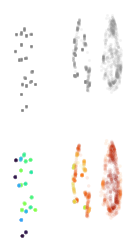

In [13]:

    ####################################################################
#################### CLUSTERING PLOT ###############################
####################################################################
# net.sigma_rec = 0
# x = net(u).detach()
# h = net.recurrent_layer(x) + net.input_layer(u)
# h = h - torch.mean(h, dim=(0, 1), keepdim=True)

# z = x - torch.mean(x, dim=[0, 1], keepdim=True)
# beta = torch.sum(h * z, dim=(0, 1)) / torch.sum(h ** 2, dim=(0, 1))
# x = (x - torch.mean(x,dim=(0,1)))/ torch.std(x,dim=(0,1))
# x = x.numpy()

x_proj  = TSNE(n_components = 2,perplexity = 400).fit_transform(x.reshape(-1,x.shape[2]).T)
fig = plt.figure(figsize=(1.5,3))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(2,1,wspace = .3)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[1,0])
sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],s=4,ax=ax0,color='gray',alpha = .1,legend = False)
#sns.kdeplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax0,color='gray',fill = True,legend = False,levels = 20,alpha = .5)

sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax1,s=6,hue = snr,alpha = .1,legend = False,palette = 'turbo')
for ax in [ax0,ax1]:
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        ax.spines['left'].set_visible(False)
        ax.axes.get_xaxis().set_visible(False)
        ax.axes.get_yaxis().set_visible(False)

plt.savefig('Figures/Figure_1_.jpg')


In [ ]:
# Convert population response to 2d array
from scipy.ndimage import gaussian_filter
embedding =(10*x_proj[:,:2]).astype(int) - (10*x_proj[:,:2]).astype(int).min()
def spatial_embedding(response,embedding,sigma):
    m = np.zeros((embedding.max()+1,embedding.max()+1))
    for neuron in range(embedding.shape[0]):
        m[embedding[neuron,1],embedding[neuron,0]] = response[neuron]
    m = np.flipud(m)
    return gaussian_filter(m,sigma)



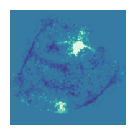

In [12]:
t = 40
trial = 0
vmin = -1
vmax = 1
sigma = 1
response = x[trial,t,:]
m = spatial_embedding(response,embedding,sigma)
fig = plt.figure(figsize=(1.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.heatmap(m ,cbar = False,ax=ax,cmap = 'mako',vmin = vmin,vmax = vmax,center=0)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
ax.set_aspect('equal')
plt.savefig('Figures/Figure_1_'+str(t)+'.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

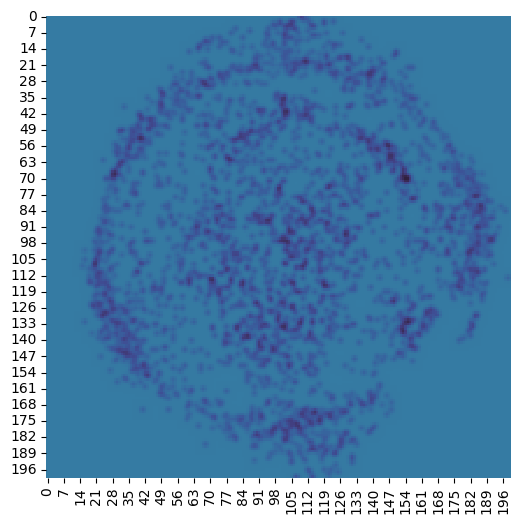

In [134]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.animation import FuncAnimation


num_frames = 75
trial = 0
data_list = [spatial_embedding(x[trial,i,:],embedding,sigma) for i in range(num_frames)]

# 2. Set up the figure and axes
fig, ax = plt.subplots(figsize=(6, 6))

def update(frame_num):
    """Updates the heatmap for each frame of the animation."""
    ax.clear()  # Clear the previous frame's axis
    current_data = data_list[frame_num]
    sns.heatmap(current_data, ax=ax, cbar=False, vmin=vmin, vmax=vmax, center=0,cmap = 'mako')

# 3. Create the animation object
# interval is the delay between frames in milliseconds
anim = FuncAnimation(fig, update, frames=num_frames, interval=200, blit=False)

# 4. Save the animation as a movie file
# You need a writer installed (e.g., 'ffmpeg' or 'pillow')
# Ensure you have the necessary writer installed (e.g., 'conda install -c conda-forge ffmpeg')
anim.save('Movies/model_1/trial_1.mp4', writer='ffmpeg', fps=5)

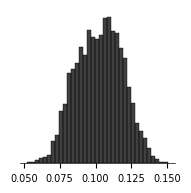

In [117]:


fig = plt.figure(figsize=(2, 2))
from scipy.spatial import ConvexHull

gs = gridspec.GridSpec(1, 1)
ax = fig.add_subplot(gs[0, 0])
sns.histplot(x = snr,ax=ax,color='black',stat = 'probability')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set_xlabel('')
#ax.set_xlim(.2,1)

ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_1_d.jpg',
            format='jpeg',

            dpi=450,
            bbox_inches='tight', transparent=True)


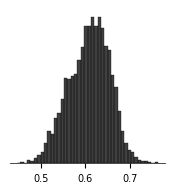

In [118]:
fig = plt.figure(figsize=(2, 2))
from scipy.spatial import ConvexHull

gs = gridspec.GridSpec(1, 1)
ax = fig.add_subplot(gs[0, 0])
sns.histplot(x = beta.detach(),ax=ax,color='black',stat = 'probability')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set_xlabel('')
#ax.set_xlim(.2,1)

ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_1_d.jpg',
            format='jpeg',

            dpi=450,
            bbox_inches='tight', transparent=True)

<Axes: xlabel='None'>

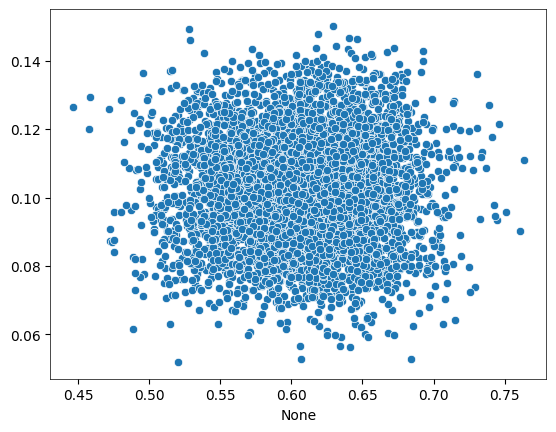

In [119]:
plt.figure()
sns.scatterplot(x = beta.detach(),y = snr)

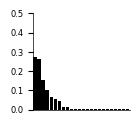

In [18]:
# Dimensionality
x = net(u)
x = (x - torch.mean(x,dim=(0,1)))/ torch.std(x,dim=(0,1))
x = x.detach().numpy()

pca = PCA().fit(x.reshape(-1,x.shape[2]))



fig = plt.figure(figsize=(1.25, 1.25))
from scipy.spatial import ConvexHull

gs = gridspec.GridSpec(1, 1)

ax = fig.add_subplot(gs[0, 0])
sns.barplot(x = np.arange(1,25),y = pca.explained_variance_ratio_[:24],color='black')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

ax.xaxis.set_tick_params(labelsize=6, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
ax.axes.get_xaxis().set_visible(False)

ax.set_ylim(0,.5)
plt.savefig('Figures/Figure_1_d.jpg',
            format='jpeg',

            dpi=450,
            bbox_inches='tight', transparent=True)


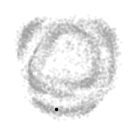

In [15]:
    ####################################################################
#################### Single neuron location ###############################
####################################################################
fixed_neuron = 51
fig = plt.figure(figsize=(1.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],s=4,ax=ax,color='gray',alpha = .1,legend = False)

sns.scatterplot(x = x_proj[None,fixed_neuron,0],y = x_proj[None,fixed_neuron,1],s=8,ax=ax,color='k',alpha = 1,legend = False)
#sns.kdeplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax0,color='gray',fill = True,legend = False,levels = 20,alpha = .5)



ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)

plt.savefig('Figures/Figure_1_.jpg')


In [16]:
#########################################################################
######################## CONNECTIVITY KERNEL ############################
#########################################################################

# Color neurons and their corresponding location by a row of the connectivity matrix.
w_rec = net.recurrent_layer.weight.detach().numpy()
embedding =(100*x_proj[:,:2]).astype(int) - (100*x_proj[:,:2]).astype(int).min()
def spatial_embedding(response,embedding,sigma):
    m = np.zeros((embedding.max()+1,embedding.max()+1))
    for neuron in range(embedding.shape[0]):
        m[embedding[neuron,1],embedding[neuron,0]] = w_rec[fixed_neuron,neuron]
    m = np.flipud(m)
    return gaussian_filter(m,sigma)


trial = 0
vmin = -.001
vmax = .001
sigma = 20
response = x[trial,t,:]
m = spatial_embedding(response,embedding,sigma)
fig = plt.figure(figsize=(1.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.heatmap(m ,cbar = False,ax=ax,cmap = 'mako', center=0,vmin = vmin,vmax = vmax,cbar_kws = {'shrink':.5})
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_1_'+str(t)+'.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

NameError: name 't' is not defined